# SmartWatt: drift-adaptive electricity anomaly detection
Run all cells (Runtime > Run all). Results appear in about a minute.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

## Data (synthetic with labelled anomalies and a usage drift)

In [2]:
"""Data loading and synthetic data generation with labelled anomalies."""


def generate_synthetic(days=180, seed=0, anomaly_rate=0.03, drift=0.4):
    """Hourly household consumption (kWh) with injected, labelled anomalies.

    Normal behaviour: morning and evening peaks, higher weekend daytime use,
    a slow seasonal drift and multiplicative noise. Four anomaly types are
    injected: spikes, sustained high use (appliance left on), unusual night
    use, and outage-like drops. Returns columns: timestamp, consumption,
    is_anomaly, anomaly_type.
    """
    rng = np.random.default_rng(seed)
    idx = pd.date_range("2024-01-01", periods=days * 24, freq="h")
    hour = idx.hour.values
    weekend = (idx.day_of_week.values >= 5).astype(float)

    base = 0.35 + 0.0 * hour
    base += 0.9 * np.exp(-0.5 * ((hour - 7.5) / 1.4) ** 2)
    base += 1.3 * np.exp(-0.5 * ((hour - 19.5) / 2.0) ** 2)
    base += weekend * 0.6 * np.exp(-0.5 * ((hour - 13) / 3.0) ** 2)
    season = 1 + 0.25 * np.sin(2 * np.pi * np.arange(len(idx)) / (24 * 365) * 2)
    value = base * season * rng.lognormal(0, 0.12, len(idx))
    # concept drift: usage level ramps up by `drift` over days 90-120 (e.g. new appliance)
    ramp = np.clip((np.arange(len(idx)) - 24 * 90) / (24 * 30), 0, 1)
    value *= 1 + drift * ramp

    label = np.zeros(len(idx), dtype=int)
    kind = np.array([""] * len(idx), dtype=object)
    n_events = int(len(idx) * anomaly_rate / 2.5)
    starts = rng.choice(np.arange(24 * 14, len(idx) - 12), n_events, replace=False)
    for s in starts:
        t = rng.choice(["spike", "sustained", "night", "drop"])
        if t == "spike":
            sl = slice(s, s + 1)
            value[sl] *= rng.uniform(2.5, 4.5)
        elif t == "sustained":
            sl = slice(s, s + rng.integers(3, 7))
            value[sl] += rng.uniform(1.2, 2.0)
        elif t == "night":
            s = s - s % 24 + rng.integers(0, 5)  # 00:00-04:00
            sl = slice(s, s + rng.integers(2, 4))
            value[sl] += rng.uniform(1.0, 2.0)
        else:
            sl = slice(s, s + rng.integers(2, 5))
            value[sl] = rng.uniform(0.0, 0.05)
        label[sl] = 1
        kind[sl] = t
    return pd.DataFrame({"timestamp": idx, "consumption": value,
                         "is_anomaly": label, "anomaly_type": kind})


def load_csv(path, timestamp_col, value_col, label_col=None, resample="h"):
    """Load a real dataset (e.g. UCI household power consumption).

    Readings are resampled to `resample` (default hourly) using the mean. If
    no label column is given, `is_anomaly` is set to -1 (unlabelled), so only
    visual / unsupervised analysis is meaningful.
    """
    cols = [c for c in (timestamp_col, value_col, label_col) if c]
    df = pd.read_csv(path, usecols=cols)
    df[timestamp_col] = pd.to_datetime(df[timestamp_col])
    df = df.set_index(timestamp_col).sort_index()
    out = df[value_col].astype(float).resample(resample).mean().interpolate().to_frame("consumption")
    if label_col:
        out["is_anomaly"] = df[label_col].resample(resample).max().fillna(0).astype(int)
    else:
        out["is_anomaly"] = -1
    out["anomaly_type"] = ""
    out.index.name = "timestamp"
    return out.reset_index()


## Features

In [3]:
"""Time-based feature extraction. All features use only past information."""

FEATURES = ["consumption", "hour_sin", "hour_cos", "is_weekend",
            "lag_1", "diff_1", "roll_mean_24", "roll_std_24", "ratio_to_roll"]


def add_features(df):
    d = df.copy()
    ts = pd.to_datetime(d["timestamp"])
    d["hour"] = ts.dt.hour
    d["is_weekend"] = (ts.dt.day_of_week >= 5).astype(int)
    d["hour_sin"] = np.sin(2 * np.pi * d["hour"] / 24)
    d["hour_cos"] = np.cos(2 * np.pi * d["hour"] / 24)
    c = d["consumption"]
    d["lag_1"] = c.shift(1)
    d["diff_1"] = c - d["lag_1"]
    past = c.shift(1)
    d["roll_mean_24"] = past.rolling(24, min_periods=6).mean()
    d["roll_std_24"] = past.rolling(24, min_periods=6).std()
    d["ratio_to_roll"] = c / (d["roll_mean_24"] + 1e-6)
    return d.dropna(subset=FEATURES).reset_index(drop=True)


## Detectors

In [4]:
"""Detectors: fixed threshold, adaptive threshold, Isolation Forest, hybrid."""



class FixedThreshold:
    """Baseline: flag readings outside mean +/- k*std of the training data."""

    def __init__(self, k=3.0):
        self.k = k

    def fit(self, train):
        self.mu = train["consumption"].mean()
        self.sd = train["consumption"].std()
        return self

    def predict(self, df):
        return (np.abs(df["consumption"] - self.mu) > self.k * self.sd).astype(int).values


def adaptive_z(df, window=14):
    """Time-aware robust z-score.

    Each reading is compared with the previous `window` readings taken at the
    same hour on the same day type (weekday/weekend). The baseline is their
    median and the scale is 1.4826*MAD, so the threshold follows daily and
    weekly routine and slowly adapts as habits change. Only past data is used.
    """
    d = df[["consumption", "hour", "is_weekend"]]
    g = d.groupby(["hour", "is_weekend"])["consumption"]
    med = g.transform(lambda s: s.shift(1).rolling(window, min_periods=4).median())
    mad = g.transform(lambda s: s.shift(1).rolling(window, min_periods=4)
                      .apply(lambda x: np.median(np.abs(x - np.median(x))), raw=True))
    scale = np.maximum(1.4826 * mad, 0.05)  # floor avoids divide-by-~0
    return ((d["consumption"] - med) / scale).values


class AdaptiveThreshold:
    """Time-aware adaptive threshold only (ablation of the hybrid)."""

    def __init__(self, k=4.0, window=14):
        self.k, self.window = k, window

    def fit(self, train):
        return self

    def predict(self, df):
        z = np.nan_to_num(adaptive_z(df, self.window))
        return (np.abs(z) > self.k).astype(int)


class IsolationForestDetector:
    """Isolation Forest on time-aware features, trained on the training split."""

    def __init__(self, contamination=0.03, seed=0):
        self.model = IsolationForest(n_estimators=200, contamination=contamination,
                                     random_state=seed)

    def fit(self, train):
        self.model.fit(train[FEATURES])
        return self

    def predict(self, df):
        return (self.model.predict(df[FEATURES]) == -1).astype(int)


class HybridAdaptive:
    """Hybrid: Isolation Forest confirmed by the adaptive threshold.

    Flag when the adaptive z-score is very high on its own (k_hi), or when
    Isolation Forest flags the point AND the reading is at least moderately
    unusual for its time slot (k_lo). The adaptive threshold suppresses IF
    false alarms on normal peaks; IF catches multivariate oddities the
    threshold alone would miss.
    """

    def __init__(self, k_hi=5.0, k_lo=2.5, contamination=0.03, window=14, seed=0):
        self.k_hi, self.k_lo, self.window = k_hi, k_lo, window
        self.iforest = IsolationForestDetector(contamination, seed)

    def fit(self, train):
        self.iforest.fit(train)
        return self

    def predict(self, df):
        z = np.abs(np.nan_to_num(adaptive_z(df, self.window)))
        iso = self.iforest.predict(df)
        return ((z > self.k_hi) | ((iso == 1) & (z > self.k_lo))).astype(int)


class DriftAdaptive:
    """Online EWMA baseline per (hour, day-type) slot.

    The baseline mean and mean absolute deviation are updated after every
    reading with rate `alpha`, so the threshold follows gradual changes in
    household usage (concept drift). Flagged readings are not used for the
    update, which stops anomalies from polluting the baseline.
    """

    def __init__(self, k=4.0, alpha=0.1, warmup=4):
        self.k, self.alpha, self.warmup = k, alpha, warmup

    def fit(self, train):
        return self

    def predict(self, df):
        mean, dev, n = {}, {}, {}
        out = np.zeros(len(df), dtype=int)
        for i, (c, h, w) in enumerate(zip(df["consumption"], df["hour"], df["is_weekend"])):
            key = (h, w)
            if key not in mean:
                mean[key], dev[key], n[key] = c, 0.05, 1
                continue
            z = abs(c - mean[key]) / max(1.25 * dev[key], 0.05)
            flag = n[key] >= self.warmup and z > self.k
            out[i] = int(flag)
            if not flag:
                dev[key] += self.alpha * (abs(c - mean[key]) - dev[key])
                mean[key] += self.alpha * (c - mean[key])
            n[key] += 1
        return out


## Evaluation

In [5]:
"""Evaluation metrics and the experiment pipeline."""



def metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "false_alarm_rate": fp / (fp + tn) if fp + tn else 0.0}


def make_detectors(seed=0):
    return {"Fixed threshold": FixedThreshold(),
            "Adaptive threshold": AdaptiveThreshold(),
            "Drift-adaptive (EWMA)": DriftAdaptive(),
            "Isolation Forest": IsolationForestDetector(seed=seed),
            "Hybrid adaptive": HybridAdaptive(seed=seed)}


def run_once(df, train_frac=0.6, seed=0):
    """Chronological split: fit on the first part, evaluate on the rest.

    Features and adaptive baselines use past data only, so predicting over the
    full series gives the test split its history without leaking the future.
    Metrics are only computed when labels exist (is_anomaly != -1).
    """
    feat = add_features(df)
    cut = int(len(feat) * train_frac)
    train, test = feat.iloc[:cut], feat.iloc[cut:]
    labelled = (test["is_anomaly"] >= 0).all()
    rows, preds = {}, {}
    for name, det in make_detectors(seed).items():
        det.fit(train)
        preds[name] = det.predict(feat)
        if labelled:
            rows[name] = metrics(test["is_anomaly"].values, preds[name][cut:])
    table = pd.DataFrame(rows).T if labelled else None
    return table, feat, preds, cut


def run_repeated(n_seeds=10, **gen_kwargs):
    """Repeat over independent synthetic datasets; return mean and std."""
    runs = [run_once(generate_synthetic(seed=s, **gen_kwargs), seed=s)[0]
            for s in range(n_seeds)]
    stack = pd.concat(runs, keys=range(n_seeds))
    return stack.groupby(level=1, sort=False).mean(), stack.groupby(level=1, sort=False).std()


## Run: mean over 10 datasets

,precision,recall,f1,false_alarm_rate
Fixed threshold,0.876,0.191,0.307,0.001
Adaptive threshold,0.755,1.000,0.856,0.011
Drift-adaptive (EWMA),0.923,1.000,0.959,0.003
Isolation Forest,0.496,0.409,0.428,0.018
Hybrid adaptive,0.832,0.986,0.901,0.006


,precision,recall,f1,false_alarm_rate
Fixed threshold,0.092,0.089,0.125,0.001
Adaptive threshold,0.111,0.000,0.082,0.003
Drift-adaptive (EWMA),0.060,0.000,0.034,0.002
Isolation Forest,0.119,0.118,0.080,0.013
Hybrid adaptive,0.062,0.011,0.035,0.002


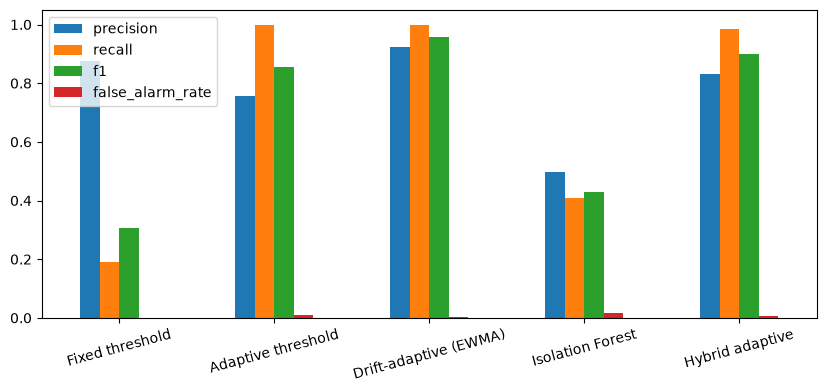

In [6]:
mean, std = run_repeated(10)
display(mean.round(3)); display(std.round(3))
mean.plot.bar(figsize=(10,4), rot=15); plt.show()

## Detections on one dataset

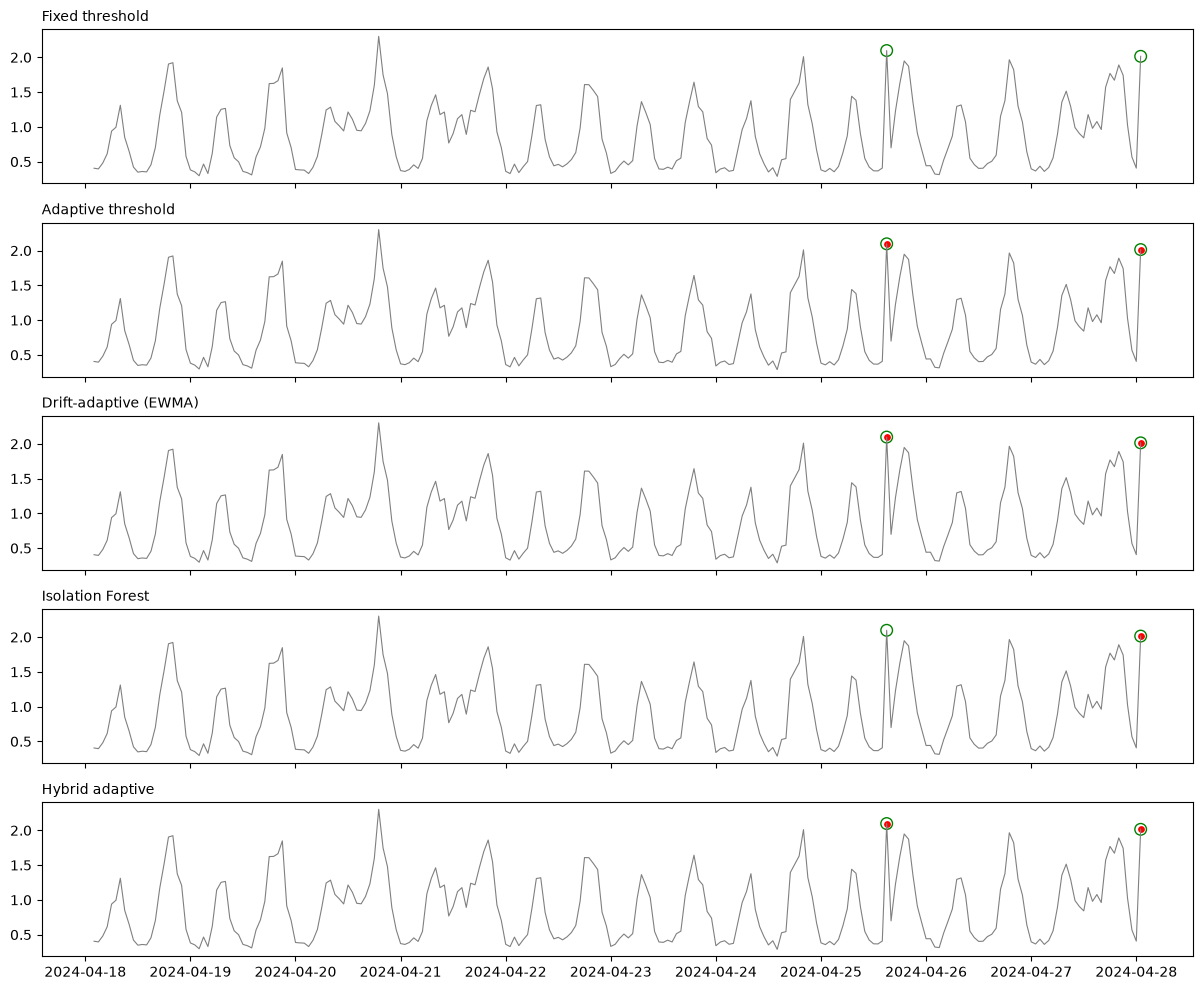

In [7]:
table, feat, preds, cut = run_once(generate_synthetic(seed=0))
win = feat.iloc[cut:cut+240]
fig, axes = plt.subplots(len(preds), 1, figsize=(12, 10), sharex=True)
for ax, (name, pr) in zip(axes, preds.items()):
    ax.plot(win['timestamp'], win['consumption'], lw=.8, color='gray')
    t = win[win['is_anomaly']==1]
    ax.scatter(t['timestamp'], t['consumption'], s=70, facecolors='none', edgecolors='green')
    f = win[pr[cut:cut+240]==1]
    ax.scatter(f['timestamp'], f['consumption'], s=15, color='red')
    ax.set_title(name, loc='left', fontsize=10)
plt.tight_layout(); plt.show()

## Optional: real data
Upload a CSV, then run `df = load_csv('file.csv', 'timestamp_col', 'value_col')` followed by `run_once(df)`.